In [23]:
# import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn.metrics as mean_squared_error
import statsmodels.api as sm

In [11]:
# load data
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/refs/heads/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df = pd.read_csv(url)

In [12]:
# extract the data for honduras
df_country = df.drop(columns=["Province/State", "Lat", "Long"]).groupby("Country/Region").sum()
series_honduras = (
    df_country.loc["Honduras"]
    .drop("Country/Region", errors="ignore")
    .astype(float)
)

In [13]:
# 5 day lag matrix
first_case_idx = (series_honduras > 0).idxmax()
series_honduras = series_honduras.loc[first_case_idx:].reset_index(drop=True)
df_honduras = pd.DataFrame({"y_t": series_honduras})
for lag in range(1, 6):
    df_honduras[f"y_lag_{lag}"] = series_honduras.shift(lag)    

In [16]:
# drop first 5 rows
df_honduras = df_honduras.dropna().reset_index(drop=True)

# fit the distributed lag model
features = ["y_lag_1", "y_lag_2", "y_lag_3", "y_lag_4", "y_lag_5"]
x_a = sm.add_constant(df_honduras[features])
y_a = df_honduras["y_t"]

model_a = sm.OLS(y_a, x_a).fit()
print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:                    y_t   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.329e+07
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:06:49   Log-Likelihood:                -8629.3
No. Observations:                1089   AIC:                         1.727e+04
Df Residuals:                    1083   BIC:                         1.730e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        327.2521     49.202      6.651      0.0

In [20]:
# predictions and residuals
y_pred_all = model_a.predict(x_a)
errors_all = y_a - y_pred_all
mse_all = np.mean(errors_all**2)

print(f"MSE (Honduras/Honduras): {mse_all:.4f}")


MSE (Honduras/Honduras): 446978.8865


In [22]:
# split honduras into halves
n_total = len(df_honduras)
split_idx = n_total // 2

# first half
train_a = df_honduras.iloc[:split_idx]
x_train_a = sm.add_constant(train_a[features])
y_train_a = train_a["y_t"]

# second half
test_a = df_honduras.iloc[split_idx:]
x_test_a = sm.add_constant(test_a[features])
y_test_a = test_a["y_t"]


In [26]:
# fit first half
model_half_a = sm.OLS(y_train_a, x_train_a).fit()

# predict second half
y_pred_half = model_half_a.predict(x_test_a)
errors_half = y_test_a - y_pred_half
mse_half = np.mean(errors_half**2)

print(f"MSE (first/second half): {mse_half:.4f}")

MSE (first/second half): 1488426.5143


<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:10: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
/var/folders/nb/9fjcppqn45ncxddq5r_bswr80000gn/T/ipykernel_95083/1119757159.py:10: SyntaxWarning: invalid escape sequence '\h'
  label="Prediction Error ($y_t - \hat{y}_t$)",
/var/folders/nb/9fjcppqn45ncxddq5r_bswr80000gn/T/ipykernel_95083/1119757159.py:18: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_ylabel("Error ($y_t - \hat{y}_t$)")


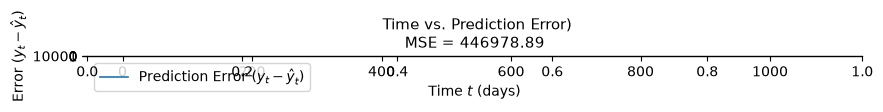

In [ ]:
# time vs prediction error plot
fig, axes = plt.subplots(2,1, figsize=(10,0), sharex=False)

# plot - all of a
axes[0].plot(
    df_honduras.index,
    errors_all,
    color="tab:blue",
    linewidth=1.2,
    label="Prediction Error ($y_t - \hat{y}_t$)",
)
axes[0].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[0].set_title(
    f" Time vs. Prediction Error)\nMSE = {mse_all:.2f}",
    fontsize=11,
)
axes[0].set_xlabel("Time $t$ (days)")
axes[0].set_ylabel("Error ($y_t - \hat{y}_t$)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)
